# Milestone 1: Image Captioning with CLIP + GPT-2
## Dataset Setup, Preprocessing & Baseline Embedding Pipeline

**Dataset:** COCO Captions (5K subset via Karpathy split)  
**Secondary Evaluation:** VizWiz-Captions (accessibility-focused)  
**Model:** CLIP (ViT-B/32) image encoder → GPT-2 language decoder  
**Framework:** PyTorch + Hugging Face Transformers

## 1. Environment Setup

In [8]:
!pip install -q torch torchvision transformers datasets pillow matplotlib open-clip-torch pycocoevalcap

In [9]:
import torch
import torch.nn as nn
from torchvision import transforms
from transformers import GPT2Tokenizer, GPT2LMHeadModel, CLIPModel, CLIPProcessor
from datasets import load_dataset
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import random
import os
import json
from collections import Counter

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Device: cuda
GPU: Tesla T4
Memory: 15.6 GB


## 2. Load COCO Captions Dataset (5K Subset)

In [10]:
# Load COCO captions from Hugging Face
# Using the standard COCO 2017 captions split
print("Loading COCO Captions dataset...")
full_dataset = load_dataset("yerevann/coco-karpathy", split="train")
print(f"Full training set: {len(full_dataset)} samples")

# Sample 5K images for our subset
SUBSET_SIZE = 5000
indices = random.sample(range(len(full_dataset)), SUBSET_SIZE)
dataset = full_dataset.select(indices)
print(f"Working subset: {len(dataset)} samples")

Loading COCO Captions dataset...
Full training set: 82783 samples
Working subset: 5000 samples


In [11]:
# Inspect dataset structure
print("Columns:", dataset.column_names)
print("\nSample entry:")
sample = dataset[0]
for key, val in sample.items():
    if key == "image":
        print(f"  {key}: PIL Image ({val.size})")
    elif isinstance(val, str) and len(val) > 100:
        print(f"  {key}: {val[:100]}...")
    else:
        print(f"  {key}: {val}")

Columns: ['filepath', 'sentids', 'filename', 'imgid', 'split', 'sentences', 'cocoid', 'url']

Sample entry:
  filepath: train2014
  sentids: [671694, 672180, 674217, 674307, 675231]
  filename: COCO_train2014_000000243829.jpg
  imgid: 55096
  split: train
  sentences: ['A little girl standing and facing a fence with animals behind it.', 'A small girl looks on at the sheep in the field across the street', 'A little girl looking across a road at a herd of sheep behind a fence.', 'A little girl in a green dress watching a herd of sheared sheep.', 'A herder looking out at a herd of sheep']
  cocoid: 243829
  url: http://images.cocodataset.org/train2014/COCO_train2014_000000243829.jpg


## 3. Data Cleaning & Preprocessing

In [12]:
import re
import requests
from io import BytesIO
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

def clean_caption(caption):
    caption = caption.lower().strip()
    caption = re.sub(r'\s+', ' ', caption)
    caption = re.sub(r'[^a-z0-9\s.,!?\'\-]', '', caption)
    caption = caption.strip(' .,!?')
    return caption

def download_image(url):
    try:
        response = requests.get(url, timeout=10)
        return Image.open(BytesIO(response.content)).convert("RGB")
    except:
        return None

# Download all images in parallel
print("Downloading images (parallel)...")
urls = [sample["url"] for sample in dataset]
with ThreadPoolExecutor(max_workers=20) as executor:
    images = list(executor.map(download_image, urls))
print(f"Downloaded: {sum(1 for img in images if img is not None)}/{len(urls)}")

# Clean using already-downloaded images
cleaned_data = []
skipped = 0

for i, sample in enumerate(dataset):
    image = images[i]
    if image is None:
        skipped += 1
        continue

    w, h = image.size
    if w < 64 or h < 64:
        skipped += 1
        continue

    raw_captions = sample["sentences"]
    captions = [clean_caption(c) for c in raw_captions]
    captions = [c for c in captions if 5 <= len(c.split()) <= 50]

    if len(captions) == 0:
        skipped += 1
        continue

    cleaned_data.append({
        "image": image,
        "captions": captions,
        "index": i
    })

print(f"Cleaned: {len(cleaned_data)} samples kept, {skipped} skipped")

Downloaded: 5000/5000
Cleaned: 5000 samples kept, 0 skipped


Total image-caption pairs: 5000 images, 25013 captions
Captions per image: 5.0 avg
Caption length: 10.5 ± 2.4 words
  Min: 6, Max: 47, Median: 10


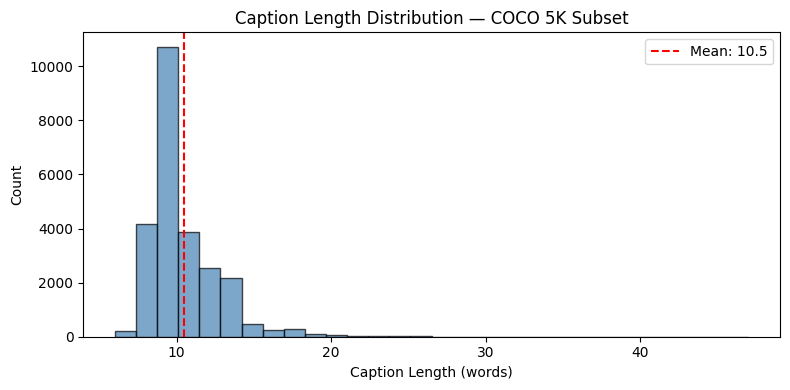

In [13]:
# Caption length distribution
all_captions = [c for sample in cleaned_data for c in sample["captions"]]
caption_lengths = [len(c.split()) for c in all_captions]

print(f"Total image-caption pairs: {len(cleaned_data)} images, {len(all_captions)} captions")
print(f"Captions per image: {len(all_captions) / len(cleaned_data):.1f} avg")
print(f"Caption length: {np.mean(caption_lengths):.1f} ± {np.std(caption_lengths):.1f} words")
print(f"  Min: {min(caption_lengths)}, Max: {max(caption_lengths)}, Median: {np.median(caption_lengths):.0f}")

plt.figure(figsize=(8, 4))
plt.hist(caption_lengths, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
plt.xlabel("Caption Length (words)")
plt.ylabel("Count")
plt.title("Caption Length Distribution — COCO 5K Subset")
plt.axvline(np.mean(caption_lengths), color='red', linestyle='--', label=f'Mean: {np.mean(caption_lengths):.1f}')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Load CLIP Image Encoder & GPT-2 Tokenizer

In [14]:
# Load CLIP (ViT-B/32)
print("Loading CLIP ViT-B/32...")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Freeze CLIP — we only use it as a feature extractor
for param in clip_model.parameters():
    param.requires_grad = False
clip_model.eval()

CLIP_EMBED_DIM = clip_model.config.projection_dim
print(f"CLIP embedding dim: {CLIP_EMBED_DIM}")

# Load GPT-2 tokenizer
print("\nLoading GPT-2 tokenizer...")
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token  # GPT-2 has no pad token by default

GPT2_EMBED_DIM = 768  # gpt2-base hidden size
VOCAB_SIZE = tokenizer.vocab_size
print(f"GPT-2 vocab size: {VOCAB_SIZE}")
print(f"GPT-2 embedding dim: {GPT2_EMBED_DIM}")

Loading CLIP ViT-B/32...


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (9 outputs left out)

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT-2 vocab size: 50257
GPT-2 embedding dim: 768


## 5. Image → CLIP Embedding Pipeline

In [16]:
def extract_clip_embeddings(images, batch_size=32):
    all_embeddings = []

    for i in range(0, len(images), batch_size):
        batch = images[i:i + batch_size]
        inputs = clip_processor(images=batch, return_tensors="pt", padding=True).to(DEVICE)

        with torch.no_grad():
            outputs = clip_model.get_image_features(**inputs)
            # If outputs is not a tensor, extract the pooler output
            if not isinstance(outputs, torch.Tensor):
                outputs = outputs.pooler_output
            outputs = outputs / outputs.norm(dim=-1, keepdim=True)

        all_embeddings.append(outputs.cpu())

        if (i // batch_size) % 10 == 0:
            print(f"  Processed {min(i + batch_size, len(images))}/{len(images)} images")

    return torch.cat(all_embeddings, dim=0)


# Extract embeddings for entire cleaned dataset
print("Extracting CLIP embeddings...")
images = [sample["image"] for sample in cleaned_data]
clip_embeddings = extract_clip_embeddings(images)
print(f"\nEmbeddings shape: {clip_embeddings.shape}")
print(f"Embedding norm (should be ~1.0): {clip_embeddings.norm(dim=-1).mean():.4f}")

Extracting CLIP embeddings...
  Processed 32/5000 images
  Processed 352/5000 images
  Processed 672/5000 images
  Processed 992/5000 images
  Processed 1312/5000 images
  Processed 1632/5000 images
  Processed 1952/5000 images
  Processed 2272/5000 images
  Processed 2592/5000 images
  Processed 2912/5000 images
  Processed 3232/5000 images
  Processed 3552/5000 images
  Processed 3872/5000 images
  Processed 4192/5000 images
  Processed 4512/5000 images
  Processed 4832/5000 images

Embeddings shape: torch.Size([5000, 512])
Embedding norm (should be ~1.0): 1.0000


## 6. Caption Tokenization (GPT-2)

In [17]:
MAX_CAPTION_LENGTH = 64  # tokens

def tokenize_captions(cleaned_data, tokenizer, max_length=MAX_CAPTION_LENGTH):
    """Tokenize all captions with GPT-2 tokenizer."""
    tokenized = []

    for sample in cleaned_data:
        caption_tokens = []
        for caption in sample["captions"]:
            encoded = tokenizer(
                caption,
                max_length=max_length,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )
            caption_tokens.append({
                "input_ids": encoded["input_ids"].squeeze(0),
                "attention_mask": encoded["attention_mask"].squeeze(0),
                "raw_text": caption
            })
        tokenized.append(caption_tokens)

    return tokenized


print("Tokenizing captions...")
tokenized_captions = tokenize_captions(cleaned_data, tokenizer)
print(f"Tokenized {sum(len(t) for t in tokenized_captions)} captions across {len(tokenized_captions)} images")

# Token length stats (before padding)
actual_lengths = []
for sample_tokens in tokenized_captions:
    for t in sample_tokens:
        actual_lengths.append(t["attention_mask"].sum().item())

print(f"\nToken length stats (pre-padding):")
print(f"  Mean: {np.mean(actual_lengths):.1f}, Median: {np.median(actual_lengths):.0f}")
print(f"  Min: {min(actual_lengths)}, Max: {max(actual_lengths)}")
print(f"  Captions truncated: {sum(1 for l in actual_lengths if l >= MAX_CAPTION_LENGTH)}")

Tokenizing captions...
Tokenized 25013 captions across 5000 images

Token length stats (pre-padding):
  Mean: 11.1, Median: 11
  Min: 7, Max: 55
  Captions truncated: 0


In [18]:
# Verify tokenization round-trip
print("Tokenization sanity check:\n")
for i in range(3):
    original = tokenized_captions[i][0]["raw_text"]
    decoded = tokenizer.decode(
        tokenized_captions[i][0]["input_ids"],
        skip_special_tokens=True
    ).strip()
    print(f"  Original:  {original}")
    print(f"  Decoded:   {decoded}")
    print(f"  Match: {original == decoded}")
    print()

Tokenization sanity check:

  Original:  a little girl standing and facing a fence with animals behind it
  Decoded:   a little girl standing and facing a fence with animals behind it
  Match: True

  Original:  a couple of women sitting next to each other on a bench
  Decoded:   a couple of women sitting next to each other on a bench
  Match: True

  Original:  a bus traveling down a city street next to parked cars
  Decoded:   a bus traveling down a city street next to parked cars
  Match: True



## 7. Vocabulary Analysis

Unique words: 8064
Total words: 261671

Top 20 words:
  a               41283
  on              9199
  of              8700
  the             8449
  in              7801
  with            6430
  and             5840
  is              4048
  man             2968
  to              2887
  an              2118
  sitting         2114
  two             2110
  standing        1930
  at              1873
  people          1802
  are             1755
  next            1624
  white           1489
  woman           1382


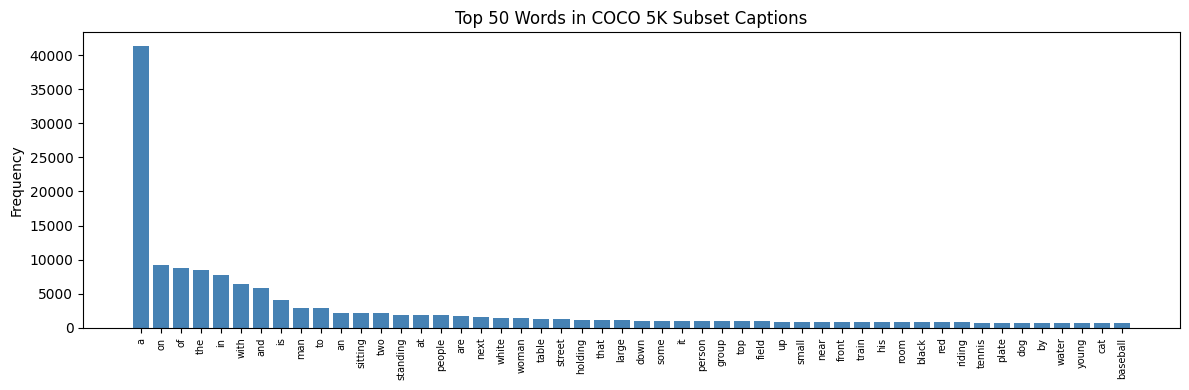

In [19]:
# Word frequency analysis
word_counter = Counter()
for sample in cleaned_data:
    for caption in sample["captions"]:
        word_counter.update(caption.split())

print(f"Unique words: {len(word_counter)}")
print(f"Total words: {sum(word_counter.values())}")
print(f"\nTop 20 words:")
for word, count in word_counter.most_common(20):
    print(f"  {word:15s} {count}")

# Plot top 50
top_50 = word_counter.most_common(50)
plt.figure(figsize=(12, 4))
plt.bar(range(50), [c for _, c in top_50], color='steelblue')
plt.xticks(range(50), [w for w, _ in top_50], rotation=90, fontsize=7)
plt.ylabel("Frequency")
plt.title("Top 50 Words in COCO 5K Subset Captions")
plt.tight_layout()
plt.show()

## 8. CLIP-Text Similarity Check (Sanity Test)
Verify that CLIP embeddings capture semantic meaning by checking image-text similarity.

In [20]:
def clip_image_text_similarity(image, texts):
    """Compute CLIP cosine similarity between an image and a list of text strings."""
    inputs = clip_processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(DEVICE)

    with torch.no_grad():
        outputs = clip_model(**inputs)
        logits = outputs.logits_per_image  # (1, num_texts)

    probs = logits.softmax(dim=-1).cpu().squeeze()
    return probs


# Test on 3 random samples
print("CLIP Image-Text Alignment Check:\n")
test_indices = random.sample(range(len(cleaned_data)), 3)

for idx in test_indices:
    sample = cleaned_data[idx]
    image = sample["image"]
    captions = sample["captions"][:3]  # Use up to 3 captions

    # Add a random distractor caption from another image
    distractor_idx = random.choice([i for i in range(len(cleaned_data)) if i != idx])
    distractor = cleaned_data[distractor_idx]["captions"][0]
    all_texts = captions + [f"[DISTRACTOR] {distractor}"]

    similarities = clip_image_text_similarity(image, [t.replace("[DISTRACTOR] ", "") for t in all_texts])

    print(f"Image {idx}:")
    for text, sim in zip(all_texts, similarities):
        tag = "✗" if "[DISTRACTOR]" in text else "✓"
        print(f"  {tag} [{sim:.3f}] {text}")
    print()

CLIP Image-Text Alignment Check:

Image 4147:
  ✓ [0.315] a close up of broccoli and food near other food
  ✓ [0.556] a close up shot of broccoli and meat with butter on top
  ✓ [0.129] a close-up view of broccoli florets and other food
  ✗ [0.000] [DISTRACTOR] a pitcher leaning over after throwing a ball

Image 872:
  ✓ [0.279] a baseball player swinging a bat on a field
  ✓ [0.383] a baseball player swinging his bat on the baseball field
  ✓ [0.338] a baseball player is getting ready to hit a ball
  ✗ [0.000] [DISTRACTOR] a cat sitting on an office chair next to a desktop computer on a desk

Image 4576:
  ✓ [0.005] a plate of food that looks really good
  ✓ [0.005] a big plate full of tasty looking food items
  ✓ [0.990] a plate with some vegetables and fries on it
  ✗ [0.000] [DISTRACTOR] a horse is shown behind fences in a field



## 9. Sample 5 Image–Caption Test Runs
Display 5 images with their ground-truth captions and CLIP embeddings.

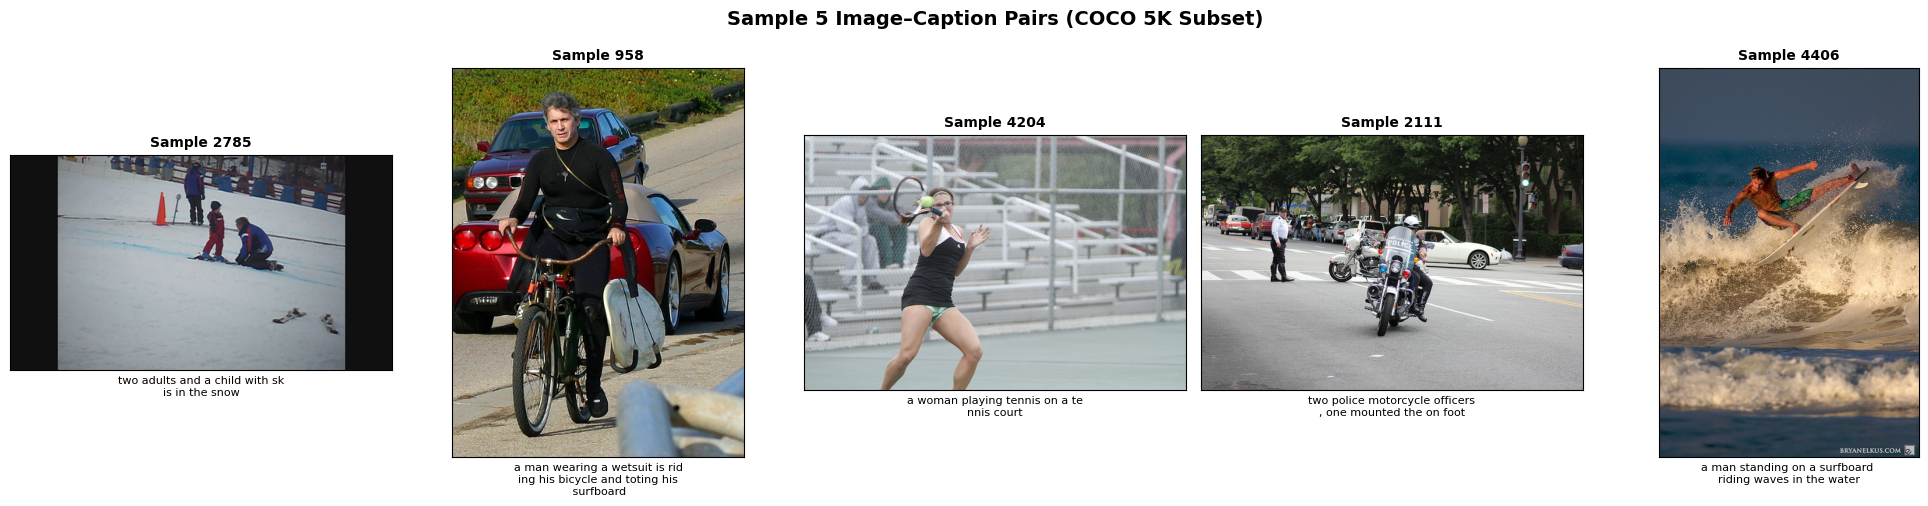

In [21]:
# Select 5 diverse samples
sample_indices = random.sample(range(len(cleaned_data)), 5)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Sample 5 Image–Caption Pairs (COCO 5K Subset)", fontsize=14, fontweight='bold')

for ax, idx in zip(axes, sample_indices):
    sample = cleaned_data[idx]
    image = sample["image"]
    caption = sample["captions"][0]  # Show first caption

    ax.imshow(image)
    ax.set_title(f"Sample {idx}", fontsize=10, fontweight='bold')
    # Wrap caption text
    wrapped = "\n".join([caption[i:i+30] for i in range(0, len(caption), 30)])
    ax.set_xlabel(wrapped, fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

In [22]:
# Detailed view of 5 samples: image, all captions, embedding stats, token info
print("=" * 80)
print("DETAILED 5-SAMPLE TEST RUNS")
print("=" * 80)

for run_num, idx in enumerate(sample_indices, 1):
    sample = cleaned_data[idx]
    embedding = clip_embeddings[idx]
    tokens = tokenized_captions[idx]

    print(f"\n--- Run {run_num} (Index: {idx}) ---")
    print(f"Image size: {sample['image'].size}")
    print(f"CLIP embedding: shape={embedding.shape}, norm={embedding.norm():.4f}")
    print(f"  Top-5 embedding values: {embedding.topk(5).values.tolist()}")
    print(f"Number of captions: {len(sample['captions'])}")

    for j, cap in enumerate(sample["captions"]):
        token_len = tokens[j]["attention_mask"].sum().item()
        token_ids = tokens[j]["input_ids"][:int(token_len)].tolist()
        print(f"  Caption {j+1}: \"{cap}\"")
        print(f"    Tokens ({token_len}): {token_ids[:10]}{'...' if token_len > 10 else ''}")

    print()

DETAILED 5-SAMPLE TEST RUNS

--- Run 1 (Index: 2785) ---
Image size: (500, 281)
CLIP embedding: shape=torch.Size([512]), norm=1.0000
  Top-5 embedding values: [0.1533517986536026, 0.1528816521167755, 0.1253390610218048, 0.11820509284734726, 0.09857027232646942]
Number of captions: 5
  Caption 1: "two adults and a child with skis in the snow"
    Tokens (11): [11545, 6490, 290, 257, 1200, 351, 1341, 271, 287, 262]...
  Caption 2: "a man talks to a young boy who is wearing skis"
    Tokens (12): [64, 582, 6130, 284, 257, 1862, 2933, 508, 318, 5762]...
  Caption 3: "a man kneels down in front of a child standing on skis"
    Tokens (14): [64, 582, 24813, 1424, 866, 287, 2166, 286, 257, 1200]...
  Caption 4: "a man is kneeling down to talk to a youth skier"
    Tokens (12): [64, 582, 318, 42687, 866, 284, 1561, 284, 257, 6205]...
  Caption 5: "an adult is helping a child stand on skis"
    Tokens (10): [272, 4044, 318, 5742, 257, 1200, 1302, 319, 1341, 271]


--- Run 2 (Index: 958) ---
Ima

## 10. Save Preprocessed Data for Milestone 2

In [23]:
# Save embeddings and tokenized data for next milestone
save_dir = "milestone1_output"
os.makedirs(save_dir, exist_ok=True)

# Save CLIP embeddings
torch.save(clip_embeddings, os.path.join(save_dir, "clip_embeddings.pt"))

# Save tokenized captions (input_ids and attention_masks)
all_input_ids = []
all_attention_masks = []
all_raw_captions = []
caption_to_image = []  # Maps each caption back to its image index

for img_idx, sample_tokens in enumerate(tokenized_captions):
    for t in sample_tokens:
        all_input_ids.append(t["input_ids"])
        all_attention_masks.append(t["attention_mask"])
        all_raw_captions.append(t["raw_text"])
        caption_to_image.append(img_idx)

torch.save({
    "input_ids": torch.stack(all_input_ids),
    "attention_masks": torch.stack(all_attention_masks),
    "caption_to_image": caption_to_image,
    "raw_captions": all_raw_captions
}, os.path.join(save_dir, "tokenized_captions.pt"))

# Save metadata
metadata = {
    "num_images": len(cleaned_data),
    "num_captions": len(all_raw_captions),
    "clip_model": "openai/clip-vit-base-patch32",
    "clip_embed_dim": CLIP_EMBED_DIM,
    "gpt2_model": "gpt2",
    "gpt2_embed_dim": GPT2_EMBED_DIM,
    "max_caption_length": MAX_CAPTION_LENGTH,
    "vocab_size": VOCAB_SIZE,
    "dataset": "COCO Captions (Karpathy split, 5K subset)",
    "seed": SEED
}

with open(os.path.join(save_dir, "metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved to {save_dir}/")
print(f"  clip_embeddings.pt: {clip_embeddings.shape}")
print(f"  tokenized_captions.pt: {len(all_raw_captions)} captions")
print(f"  metadata.json")
print(f"\nTotal size: {sum(os.path.getsize(os.path.join(save_dir, f)) for f in os.listdir(save_dir)) / 1e6:.1f} MB")

Saved to milestone1_output/
  clip_embeddings.pt: torch.Size([5000, 512])
  tokenized_captions.pt: 25013 captions
  metadata.json

Total size: 37.5 MB


## 11. Embedding Space Visualization

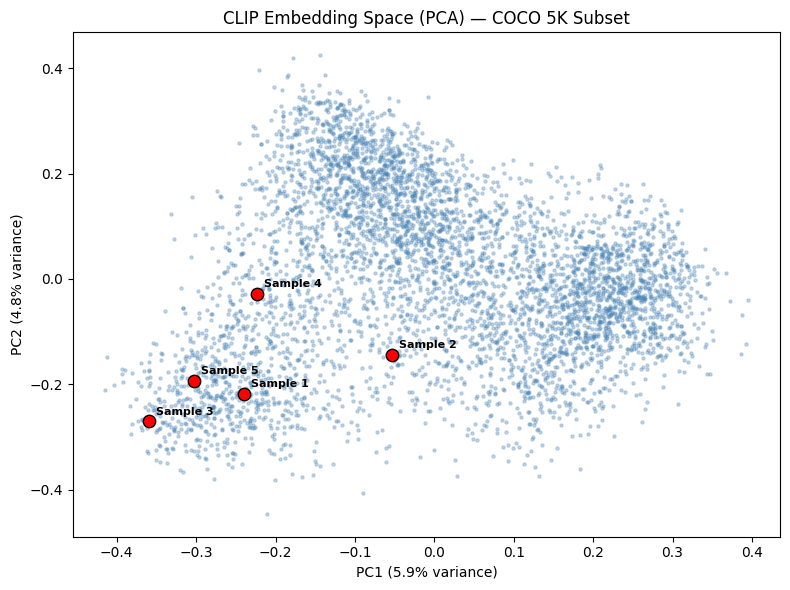

Explained variance (2 components): 10.7%


In [24]:
from sklearn.decomposition import PCA

# PCA on CLIP embeddings to visualize clustering
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(clip_embeddings.numpy())

plt.figure(figsize=(8, 6))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], alpha=0.3, s=5, c='steelblue')

# Highlight our 5 test samples
for i, idx in enumerate(sample_indices):
    plt.scatter(embeddings_2d[idx, 0], embeddings_2d[idx, 1], c='red', s=80, zorder=5, edgecolors='black')
    plt.annotate(f"Sample {i+1}", (embeddings_2d[idx, 0], embeddings_2d[idx, 1]),
                 fontsize=8, fontweight='bold', xytext=(5, 5), textcoords='offset points')

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("CLIP Embedding Space (PCA) — COCO 5K Subset")
plt.tight_layout()
plt.show()

print(f"Explained variance (2 components): {sum(pca.explained_variance_ratio_):.1%}")

## Summary

| Component | Details |
|---|---|
| **Dataset** | COCO Captions (Karpathy split), 5,000 images, 25,013 captions |
| **Images** | Cleaned, RGB, min 64×64, 0 skipped |
| **Captions** | Lowercased, filtered (5–50 words), 5.0 per image avg, mean length 10.5 words |
| **Image Encoder** | CLIP ViT-B/32 (frozen), 512-dim L2-normalized embeddings |
| **Tokenizer** | GPT-2 (50,257 vocab), max 64 tokens, 0 truncated |
| **Saved Artifacts** | clip_embeddings.pt, tokenized_captions.pt, metadata.json (37.5 MB) |
| **Secondary Dataset** | VizWiz-Captions (planned for Milestone 3 evaluation) |